In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
import json
from PIL import Image
from tqdm.auto import tqdm

## 1. Table data

In [2]:
ROOT = Path("/kaggle/input/competitions/cassava-leaf-disease-classification")
IMAGES_DIR = ROOT / "train_images"
SEED = 42

df = pd.read_csv(ROOT / "train.csv")
df.head()

,image_id,label
0,1000015157.jpg,0
1,1000201771.jpg,3
2,100042118.jpg,1
3,1000723321.jpg,1
4,1000812911.jpg,3


In [3]:
class_map_path = ROOT / "label_num_to_disease_map.json"
with open(class_map_path, encoding="utf-8") as file:
    class_names = {
        int(label): name
        for label, name in json.load(file).items()
    }
    
for id, name in class_names.items():
    print(f"{id} - {name}")

0 - Cassava Bacterial Blight (CBB)
1 - Cassava Brown Streak Disease (CBSD)
2 - Cassava Green Mottle (CGM)
3 - Cassava Mosaic Disease (CMD)
4 - Healthy


In [4]:
print("Rows duplicates:", df.duplicated().sum())
print("image_id duplicates:", df["image_id"].duplicated().sum())
print("Unknown class_names:", (~df["label"].isin(class_names)).sum())
print(f"Rows count: {len(df):,}")
print("Missing data:")
display(df.isna().sum())

Rows duplicates: 0
image_id duplicates: 0
Unknown class_names: 0
Rows count: 21,397
Missing data:


image_id    0
label       0
dtype: int64

## 2. Classes balance

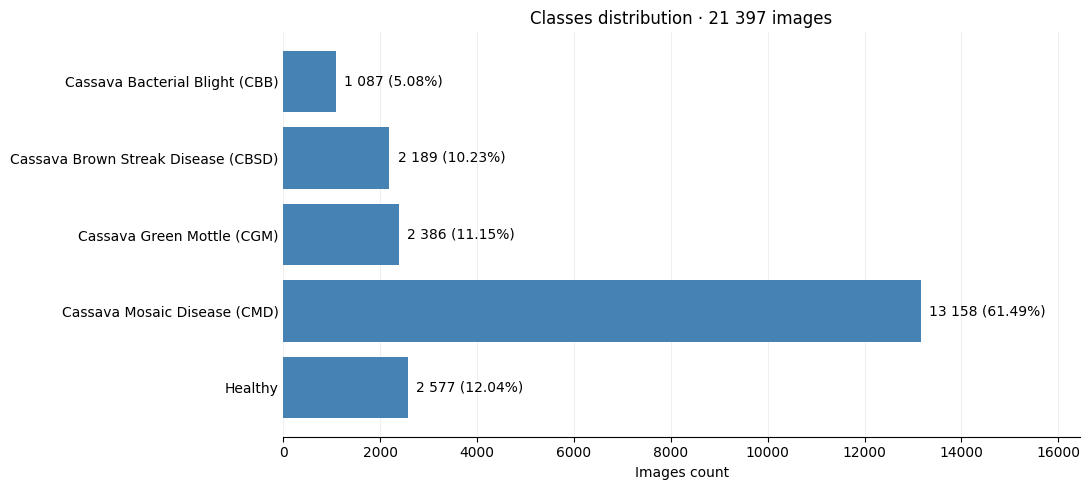

In [5]:
class_ids = sorted(class_names)
class_counts = df["label"].value_counts().reindex(class_ids, fill_value=0)

class_stats = pd.DataFrame(
    {
        "class_name": [class_names[label] for label in class_ids],
        "count": class_counts.to_numpy(),
        "percent": (class_counts.to_numpy() / len(df) * 100).round(2),
    },
    index=pd.Index(class_ids, name="label"),
)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    class_stats["class_name"],
    class_stats["count"],
    color="steelblue",
)

labels = [
    f"{count:,} ({percent:.2f}%)".replace(",", " ")
    for count, percent in zip(class_stats["count"], class_stats["percent"])
]

ax.bar_label(bars, labels=labels, padding=6, fontsize=10)

ax.set(
    xlabel="Images count",
    title=f"Сlasses distribution · {len(df):,} images".replace(",", " "),
)
ax.invert_yaxis()
ax.margins(x=0.25)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

Big imbalance into CMD class

## 3. Images size

Reading image sizes:   0%|          | 0/21397 [00:00<?, ?it/s]

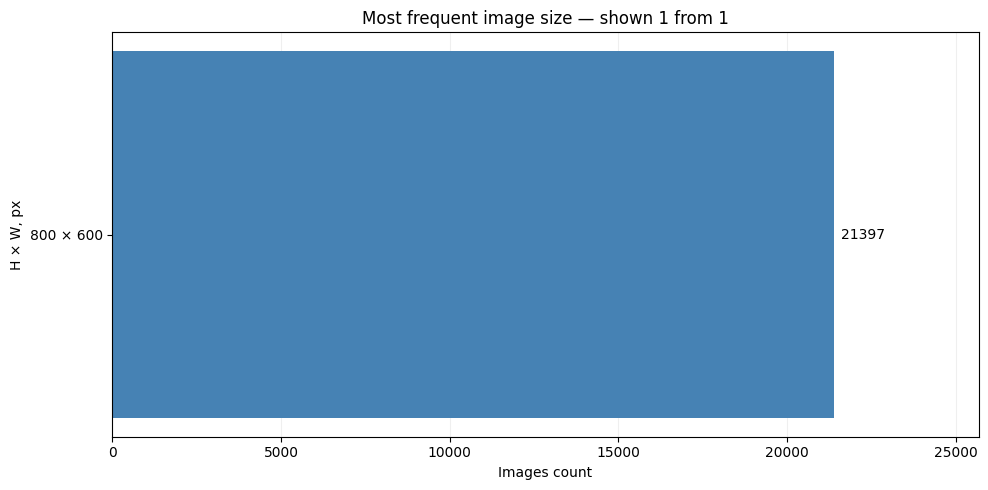

In [6]:
image_records = []

for image_id in tqdm(df["image_id"], desc="Reading image sizes"):
    with Image.open(IMAGES_DIR / image_id) as image:
        width, height = image.size

    image_records.append({
        "image_id": image_id,
        "width": width,
        "height": height,
    })

image_stats = pd.DataFrame(image_records)
image_stats["aspect_ratio"] = (
    image_stats["width"] / image_stats["height"]
)

size_counts = (
    image_stats.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

top_sizes = size_counts.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    [f"{width} × {height}" for width, height in top_sizes.index],
    top_sizes.to_numpy(),
    color="steelblue",
)

ax.bar_label(bars, padding=5)
ax.margins(x=0.2)

ax.set(
    xlabel="Images count",
    ylabel="H × W, px",
    title=f"Most frequent image size — shown {len(top_sizes)} from {len(size_counts)}",
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

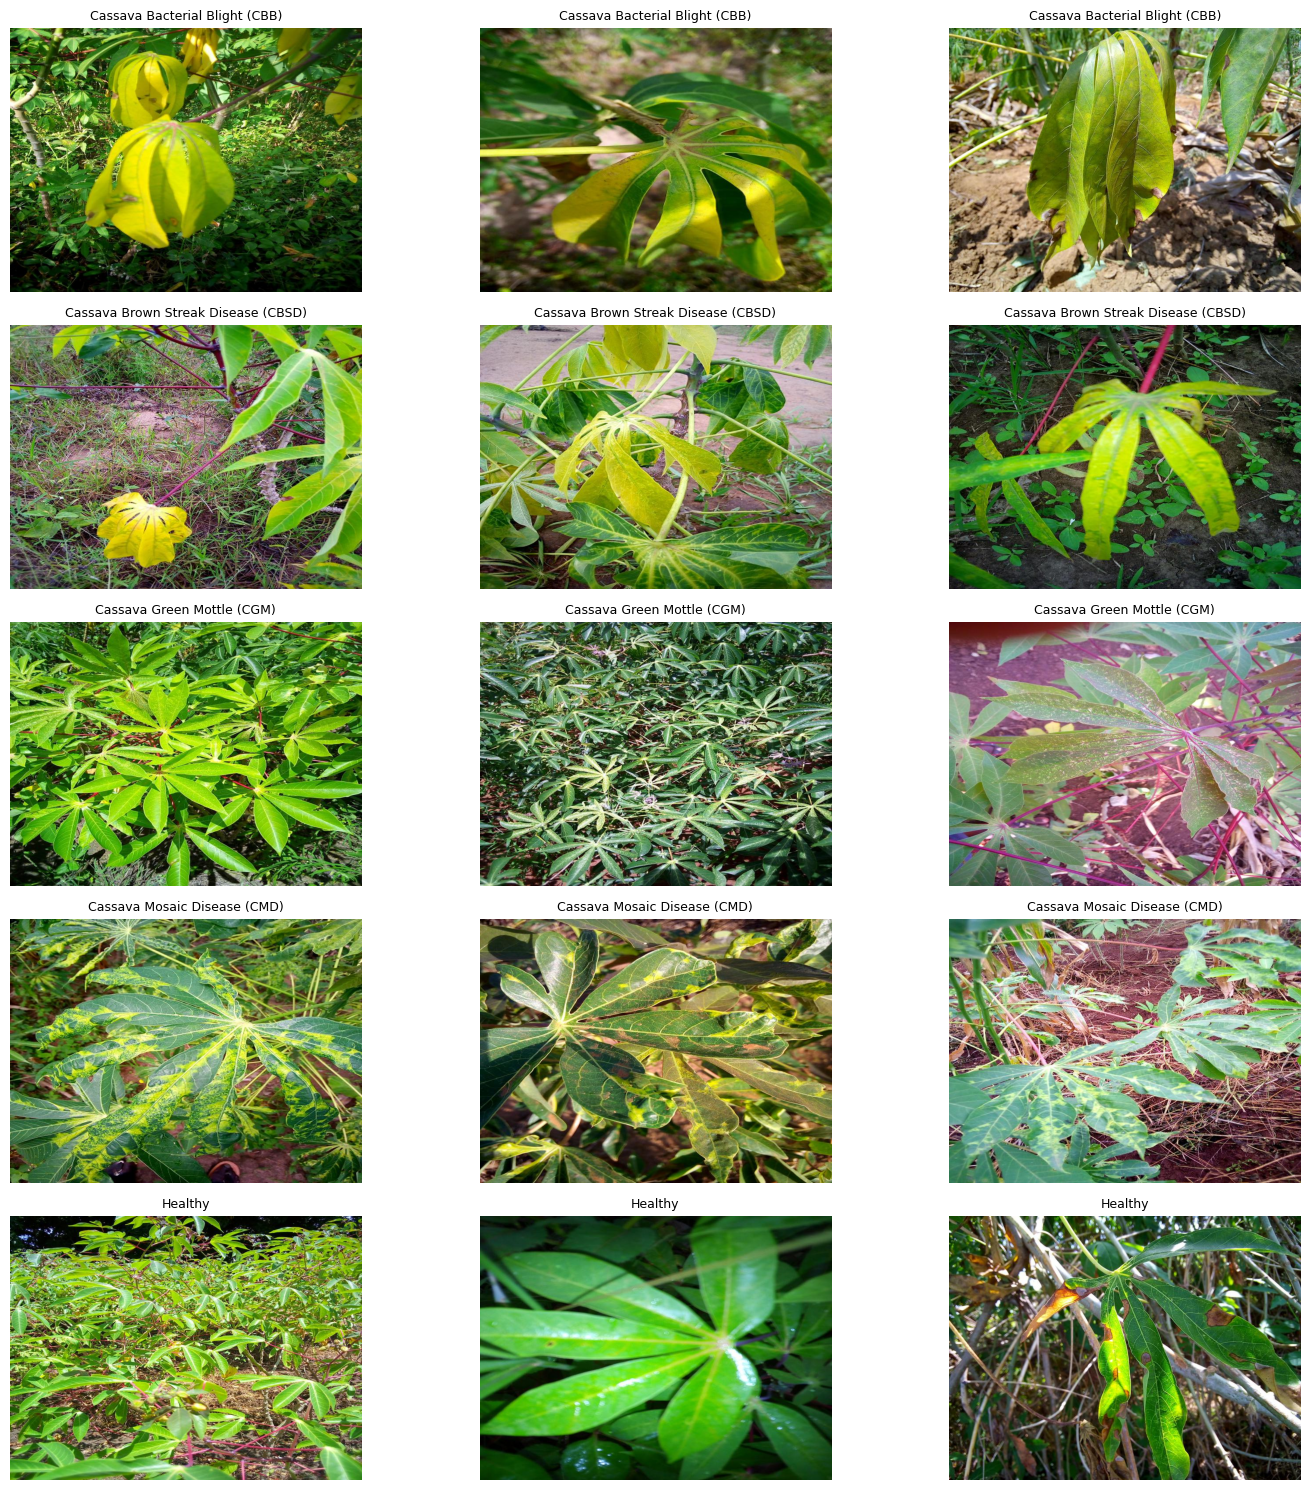

In [7]:
n_per_class = 3

fig, axes = plt.subplots(
    nrows=len(class_ids),
    ncols=n_per_class,
    figsize=(15, len(class_ids) * 3),
    squeeze=False,
)

for ax in axes.flat:
    ax.axis("off")

for row, label in enumerate(class_ids):
    class_df = df[df["label"] == label]

    examples = class_df.sample(
        n=min(n_per_class, len(class_df)),
        random_state=SEED,
    )

    for col, image_id in enumerate(examples["image_id"]):
        with Image.open(IMAGES_DIR / image_id) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].set_title(
            class_names[label],
            fontsize=9,
        )

plt.tight_layout()
plt.show()

As i see in a first glance, cassave bacterial blight (CBB) is similar to cassave brown streak disaese (CBSD) and cassave green mottle disease (CGM) is hard to notice

## Conclusion

- The dataset contains 21,397 images across 5 classes
- No missing values, duplicates, unknown labels
- Imbalance with CMD class

Will try to reduce classes imbalance with class-weghted loss and analyse results with per class metrics